# Data Engineer Skills Analysis — Visualizations

This notebook visualizes the results of three SQL queries analyzing remote Data Engineer job postings:

1. **Most In-Demand Skills** — Top 10 skills by demand count
2. **Highest-Paying Skills** — Top 25 skills by median salary (min. 100 postings)
3. **Optimal Skills** — Balancing demand and salary via log-demand × median-salary score

Each table from the query outputs is hardcoded below for reproducibility.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Consistent style
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## 1. Most In-Demand Skills for Data Engineers (Remote)
Top 10 skills by number of remote job postings mentioning them.

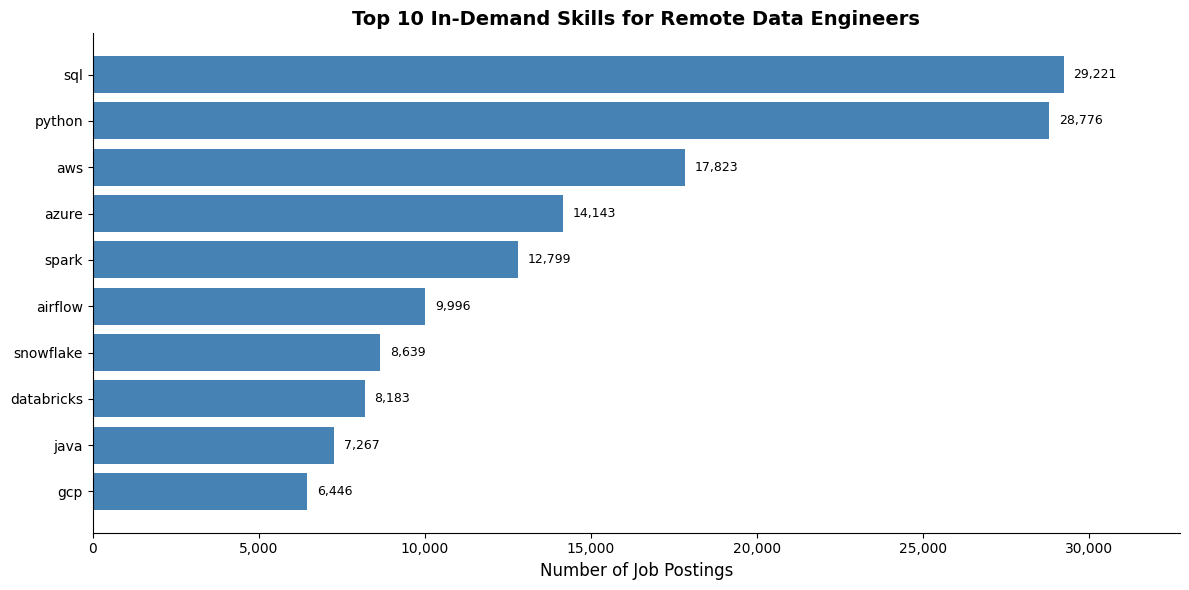

In [5]:
demand_data = {
    'skills': ['sql', 'python', 'aws', 'azure', 'spark', 'airflow', 'snowflake', 'databricks', 'java', 'gcp'],
    'demand_count': [29221, 28776, 17823, 14143, 12799, 9996, 8639, 8183, 7267, 6446]
}
df_demand = pd.DataFrame(demand_data)

fig, ax = plt.subplots()
bars = ax.barh(df_demand['skills'][::-1], df_demand['demand_count'][::-1], color='steelblue')
ax.set_xlabel('Number of Job Postings')
ax.set_title('Top 10 In-Demand Skills for Remote Data Engineers')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
for bar, val in zip(bars, df_demand['demand_count'][::-1]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
ax.set_xlim(0, max(df_demand['demand_count']) * 1.12)
plt.tight_layout()
plt.show()

**Takeaways:**
- SQL and Python are nearly tied at ~29,000 postings — foundational skills.
- AWS leads cloud platforms (~18k), followed by Azure (~14k).
- Spark rounds out the top 5; Airflow, Snowflake, Databricks show strong pipeline-tool demand.
- Java and GCP complete the top 10.

## 2. Highest-Paying Skills for Data Engineers (Remote, min. 100 postings)
Median salary per skill, with skill frequency shown via bar color intensity.

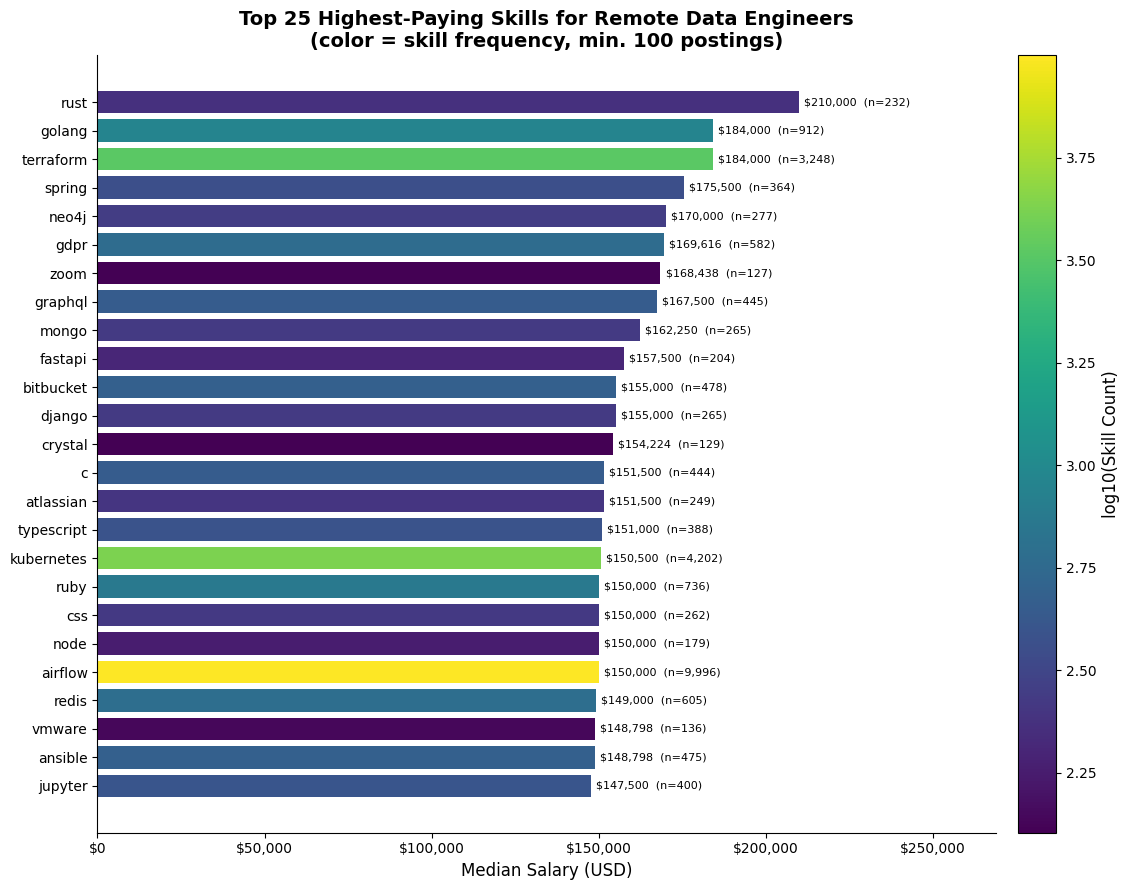

In [6]:
salary_data = {
    'skills': ['rust', 'golang', 'terraform', 'spring', 'neo4j', 'gdpr', 'zoom', 'graphql',
               'mongo', 'fastapi', 'bitbucket', 'django', 'crystal', 'c', 'atlassian',
               'typescript', 'kubernetes', 'ruby', 'css', 'node', 'airflow', 'redis',
               'vmware', 'ansible', 'jupyter'],
    'median_salary': [210000, 184000, 184000, 175500, 170000, 169616, 168438, 167500,
                      162250, 157500, 155000, 155000, 154224, 151500, 151500,
                      151000, 150500, 150000, 150000, 150000, 150000, 149000,
                      148798, 148798, 147500],
    'skill_count': [232, 912, 3248, 364, 277, 582, 127, 445,
                    265, 204, 478, 265, 129, 444, 249,
                    388, 4202, 736, 262, 179, 9996, 605,
                    136, 475, 400]
}
df_salary = pd.DataFrame(salary_data)

fig, ax = plt.subplots(figsize=(12, 9))
norm = plt.Normalize(np.log10(df_salary['skill_count'].min()), np.log10(df_salary['skill_count'].max()))
colors = plt.cm.viridis(norm(np.log10(df_salary['skill_count'])))
bars = ax.barh(df_salary['skills'][::-1], df_salary['median_salary'][::-1], color=colors[::-1])

ax.set_xlabel('Median Salary (USD)')
ax.set_title('Top 25 Highest-Paying Skills for Remote Data Engineers\n(color = skill frequency, min. 100 postings)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${int(x):,}"))
for bar, sal, cnt in zip(bars, df_salary['median_salary'][::-1], df_salary['skill_count'][::-1]):
    ax.text(bar.get_width() + 1500, bar.get_y() + bar.get_height()/2,
            f"${sal:,}  (n={cnt:,})", va='center', fontsize=8)
ax.set_xlim(0, max(df_salary['median_salary']) * 1.28)

sm = plt.cm.ScalarMappable(cmap='viridis', norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label('log10(Skill Count)')

plt.tight_layout()
plt.show()

**Takeaways:**
- **Rust** tops the pay scale at $210k (but only 232 postings — niche).
- **Go** ($184k) and **Terraform** ($184k) combine high pay with meaningful frequency (912 and 3,248).
- **Kubernetes** ($150.5k, 4,202) and **Airflow** ($150k, 9,996) are the highest-frequency high-payers.
- Practical sweet spot: Terraform, Go, Kubernetes, Airflow.

## 3. Most Optimal Skills — Balancing Demand & Salary
Optimal score = ln(demand_count) × median_salary / 1,000,000. Only skills with ≥100 remote postings and specified salaries.

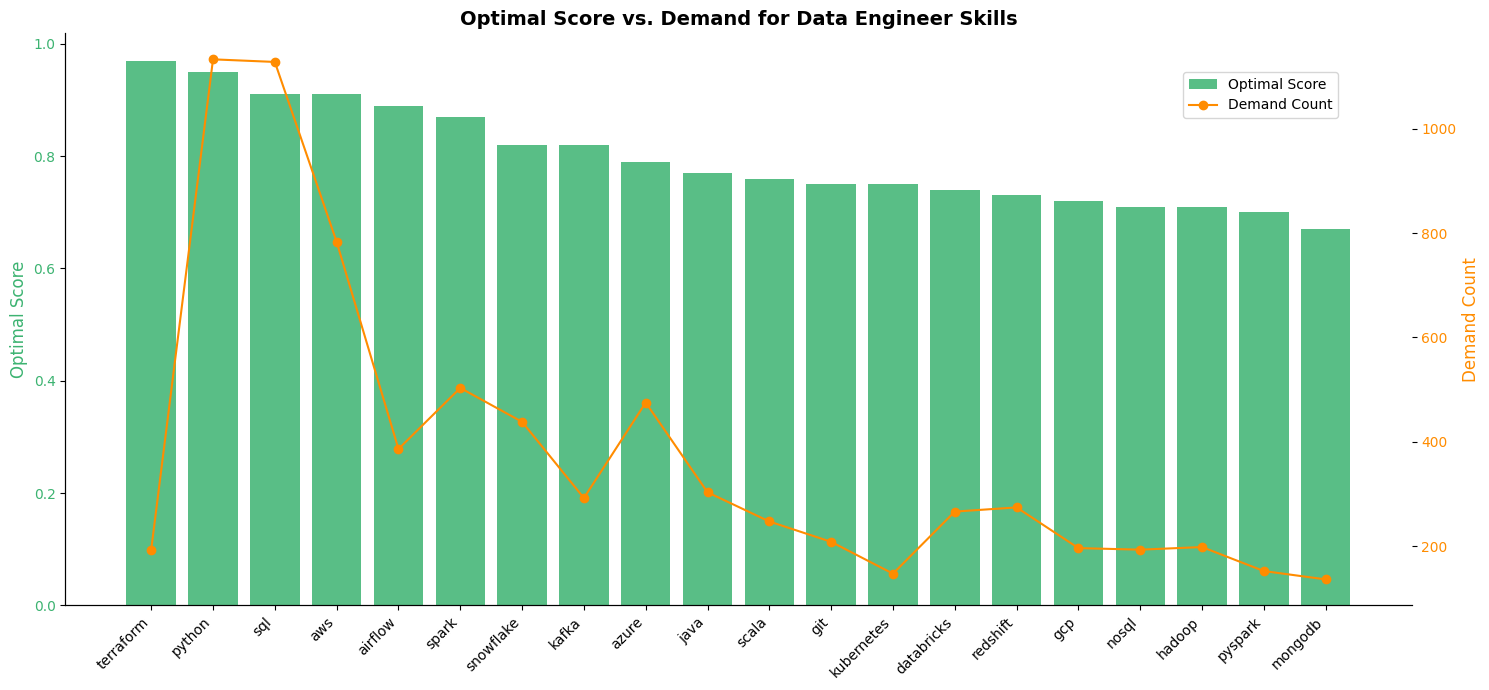

In [10]:
optimal_data = {
    'skills': ['terraform', 'python', 'sql', 'aws', 'airflow', 'spark', 'snowflake', 'kafka',
               'azure', 'java', 'scala', 'git', 'kubernetes', 'databricks', 'redshift',
               'gcp', 'nosql', 'hadoop', 'pyspark', 'mongodb'],
    'median_salary': [184000, 135000, 130000, 137320.3, 150000, 140000, 135500, 145000,
                      128000, 135000, 137290.5, 140000, 150500, 132750, 130000,
                      136000, 134415, 135000, 140000, 135750],
    'demand_count': [193, 1133, 1128, 783, 386, 503, 438, 292,
                     475, 303, 247, 208, 147, 266, 274,
                     196, 193, 198, 152, 136],
    'optimal_score': [0.97, 0.95, 0.91, 0.91, 0.89, 0.87, 0.82, 0.82,
                      0.79, 0.77, 0.76, 0.75, 0.75, 0.74, 0.73,
                      0.72, 0.71, 0.71, 0.70, 0.67]
}
data = pd.DataFrame(optimal_data)

# FIX 1: 'data' is a DataFrame, not a list of tuples — use column access, not d[0], d[3], d[2]
skills = data['skills'].tolist()
scores = data['optimal_score'].tolist()
demand = data['demand_count'].tolist()

x = np.arange(len(skills))
fig, ax1 = plt.subplots(figsize=(15, 7))

# FIX 2: ax1.bar returns a BarContainer, not a single label — capture handles for the legend
bars1 = ax1.bar(x, scores, color="mediumseagreen", alpha=0.85, label="Optimal Score")
ax1.set_ylabel("Optimal Score", color="mediumseagreen")
ax1.tick_params(axis="y", labelcolor="mediumseagreen")
ax1.set_xticks(x)
ax1.set_xticklabels(skills, rotation=45, ha="right")

ax2 = ax1.twinx()
# FIX 3: capture the line handle separately for the combined legend
line1, = ax2.plot(x, demand, "o-", color="darkorange", label="Demand Count")
ax2.set_ylabel("Demand Count", color="darkorange")
ax2.tick_params(axis="y", labelcolor="darkorange")

# FIX 4: build a single combined legend from both axes (the original fig.legend
#        with no handles would only pick up artists attached to the figure,
#        which is unreliable; use explicit handles)
handles = [bars1, line1]
labels = [h.get_label() for h in handles]
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.9, 0.9))

plt.title("Optimal Score vs. Demand for Data Engineer Skills")
plt.tight_layout()
plt.savefig("optimal_score_vs_demand.png", dpi=150)
plt.show()

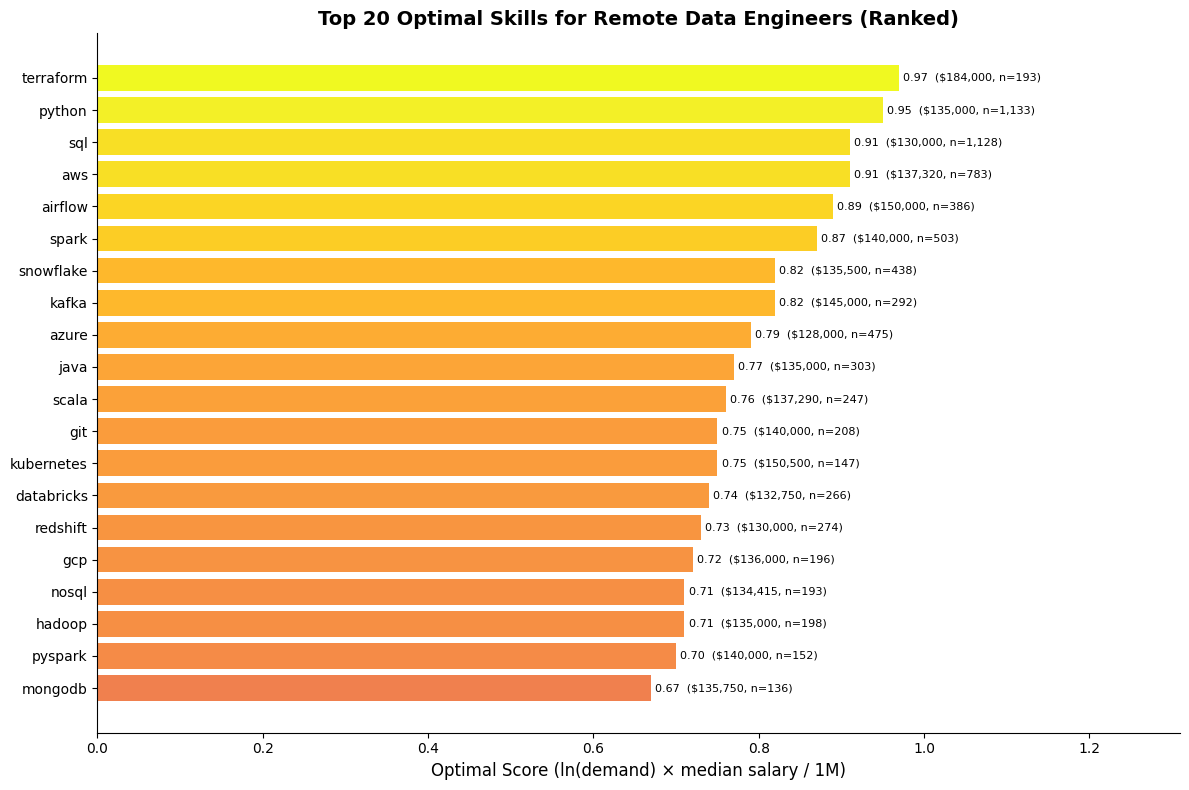

In [8]:
fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(df_opt['skills'][::-1], df_opt['optimal_score'][::-1],
               color=plt.cm.plasma(df_opt['optimal_score'][::-1] / df_opt['optimal_score'].max()))
ax.set_xlabel('Optimal Score (ln(demand) × median salary / 1M)')
ax.set_title('Top 20 Optimal Skills for Remote Data Engineers (Ranked)')
for bar, score, sal, cnt in zip(bars,
                                df_opt['optimal_score'][::-1],
                                df_opt['median_salary'][::-1],
                                df_opt['demand_count'][::-1]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f"{score:.2f}  (${int(sal):,}, n={cnt:,})", va='center', fontsize=8)
ax.set_xlim(0, max(df_opt['optimal_score']) * 1.35)
plt.tight_layout()
plt.show()

**Takeaways:**
- **Terraform** leads (0.97) — highest pay among frequently-requested skills ($184k, 193 postings).
- **Python** (0.95) and **SQL** (0.91) are the highest-volume skills with strong pay.
- **AWS** (0.91) and **Airflow** (0.89) balance cloud/pipeline demand with competitive salaries.
- The optimal-score metric prevents rare outliers (e.g., Rust) from dominating — practical learning priorities: **Terraform, Python, SQL, AWS, Airflow**.

## Summary

| Analysis | Top Skill | Key Insight |
|---|---|---|
| Demand | SQL (29,221) | SQL & Python are non-negotiable foundations |
| Salary | Rust ($210k) | Niche languages pay most but are rare |
| Optimal | Terraform (0.97) | Terraform, Python, SQL, AWS, Airflow offer the best demand/pay balance |